# Grover's algorithm

**Grover's search with the Qiskit primitives** — the IBM Quantum tutorial, annotated.

**Where it sits in the study path.** `14_Simple_Grover` built Grover's search by hand on 2 and 3 qubits and
`15_Grover_Algorithm` is the full textbook chapter (oracle, diffuser, number of iterations, a sudoku as a
satisfiability problem). This notebook is **the same algorithm with the modern tools**: the oracle is a
multi-controlled Z (`MCMTGate`) sandwiched by X gates, the Grover iterate comes ready-made from
`grover_operator`, the circuit is transpiled with `generate_preset_pass_manager` and executed with the
`SamplerV2` primitive — the four steps of a *Qiskit pattern*: map, optimize, execute, post-process.

> Backend: this is the **IBM / Aer** edition — the `../IQM` folder has the IQM Garnet/Emerald edition. With a saved IBM Quantum account the circuit runs on the least busy IBM device; without one the `QiskitRuntimeService` cell prints a message and the same `Sampler` runs on the local `AerSimulator`.


*Estimated QPU usage: 4 seconds (tested on IBM Nairobi)*

## Background

Amplitude amplification is a general purpose quantum algorithm, or subroutine, that can be used to obtain a quadratic speedup over a handful of classical algorithms. [Grover’s algorithm](https://arxiv.org/abs/quant-ph/9605043) was the first to demonstrate this speedup on unstructured search problems. Formulating a Grover's search problem requires an oracle function that marks one or more computational basis states as the states we are interested in finding, and an amplification circuit that increases the amplitude of marked states, consequently suppressing the remaining states.

Here, we demonstrate how to construct Grover oracles and use the `grover_operator` function (formerly the `GroverOperator` class) from the Qiskit circuit library to easily set up a Grover's search instance. The runtime `Sampler` primitive allows seamless execution of Grover circuits.


## Requirements

Before starting this tutorial, ensure that you have the following installed:

* Qiskit SDK 1.0 or later, with visualization support (`pip install 'qiskit[visualization]'`)
* Qiskit Runtime (`pip install qiskit-ibm-runtime`) 0.22 or later


## Step 1. Map classical inputs to a quantum problem

Grover's algorithm requires an [oracle](https://learning.quantum-computing.ibm.com/course/fundamentals-of-quantum-algorithms/grovers-algorithm) that specifies one or more marked computational basis states, where "marked" means a state with a phase of -1.  A controlled-Z gate, or its multi-controlled generalization over $N$ qubits, marks the $2^{N}-1$ state (`'1'`\*$N$ bit-string).  Marking basis states with one or more `'0'` in the binary representation requires applying X-gates on the corresponding qubits before and after the controlled-Z gate; equivalent to having an open-control on that qubit.  In the following code, we define an oracle that does just that, marking one or more input basis states defined through their bit-string representation.  The `MCMTGate` (formerly `MCMT`) is used to implement the multi-controlled Z-gate.


### Setup

Here we import the small number of tools we need for this tutorial.


In [1]:
# Built-in modules
import math                                              # math.pi, math.asin, math.sqrt, math.floor

# Imports from Qiskit
from qiskit import QuantumCircuit                        # the object we build circuits with
from qiskit.circuit.library import grover_operator, MCMTGate, ZGate   # Grover iterate builder (formerly the GroverOperator class); multi-controlled multi-target gate (formerly MCMT); Pauli Z
from qiskit.visualization import plot_distribution       # bar chart of a probability distribution (normalised counts)
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

# Imports from Qiskit Runtime
from qiskit_ibm_runtime import QiskitRuntimeService      # IBM Quantum account / connection object
from qiskit_ibm_runtime import SamplerV2 as Sampler      # the Sampler primitive: a real device, or local testing mode on a simulator
from qiskit_aer import AerSimulator                      # added: the local simulator used when no IBM account is available


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `grover_operator`, `MCMTGate` | the current names: the tutorial's `GroverOperator` class (deprecated in Qiskit 2.1, removed in 3.0) and `MCMT` (deprecated since 1.4) were replaced by them |
| `plot_distribution` | like `plot_histogram`, but the bars are probabilities (counts / shots) |
| `QiskitRuntimeService`, `Sampler` | the IBM account and the Runtime SamplerV2; given a simulator instead of a device the Sampler runs in *local testing mode* |
| `AerSimulator` | added: the fallback backend when no account is saved |
| `draw(qc)` | our helper around `qc.draw("mpl", style="clifford")`; `display(...)` shows a figure from anywhere in a cell |

</details>


In [2]:
# To run on hardware, select the backend with the fewest number of jobs in the queue
try:
    service = QiskitRuntimeService(channel="ibm_quantum_platform")   # load the account saved for IBM Quantum Platform
    backend = service.least_busy(operational=True, simulator=False)  # the real device with the shortest queue
except Exception as e:                                   # AccountNotFoundError without a saved account
    service = None
    backend = AerSimulator()                             # added: fall back to the local simulator
    print(f"⚠ No IBM Quantum account ({type(e).__name__}): the Sampler below runs on the local AerSimulator.")
backend.name


⚠ No IBM Quantum account (AccountNotFoundError): the Sampler below runs on the local AerSimulator.


'aer_simulator'

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QiskitRuntimeService(channel="ibm_quantum_platform")` | loads the account saved for the IBM Quantum Platform (the old `ibm_quantum` channel was retired in 2025); without one it raises |
| `service.least_busy(operational=True, simulator=False)` | the working real device with the shortest queue |
| `except` → `AerSimulator()` | added: offline the notebook continues on the local simulator instead of stopping; `backend.name` then shows `aer_simulator` |

</details>


In [3]:
def grover_oracle(marked_states):
    """Build a Grover oracle for multiple marked states

    Here we assume all input marked states have the same number of bits

    Parameters:
        marked_states (str or list): Marked states of oracle

    Returns:
        QuantumCircuit: Quantum circuit representing Grover oracle
    """
    if not isinstance(marked_states, list):              # a single string is accepted too
        marked_states = [marked_states]
    # Compute the number of qubits in circuit
    num_qubits = len(marked_states[0])

    qc = QuantumCircuit(num_qubits)
    # Mark each target state in the input list
    for target in marked_states:
        # Flip target bit-string to match Qiskit bit-ordering
        rev_target = target[::-1]                        # [::-1] = the string reversed: character i is now qubit i
        # Find the indices of all the '0' elements in bit-string
        zero_inds = [ind for ind in range(num_qubits) if rev_target.startswith("0", ind)]   # startswith("0", ind): is character ind a '0'?
        # Add a multi-controlled Z-gate with pre- and post-applied X-gates (open-controls)
        # where the target bit-string has a '0' entry
        qc.x(zero_inds)                                  # X on a list of qubits = one X on each
        qc.compose(MCMTGate(ZGate(), num_qubits - 1, 1), inplace=True)   # Z on the last qubit controlled by all the others: phase -1 on |11...1> only
        qc.x(zero_inds)                                  # undo the X gates
    return qc


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `target[::-1]` | Qiskit writes qubit 0 as the *rightmost* character: reversing makes index i = qubit i |
| `MCMTGate(ZGate(), n − 1, 1)` | a Z on one target controlled by the other $n-1$ qubits: it multiplies $\|11…1⟩$ by −1 and leaves every other basis state alone (the tutorial's `MCMT` is deprecated) |
| `qc.x(zero_inds)` before and after | turns the marked string into $11…1$ for the controlled Z and back: an *open control* on each 0 |
| `for target in marked_states` | one such block per marked state: each block flips the sign of one basis state |

</details>


### Specific Grover's instance

Now that we have the oracle function, we can define a specific instance of Grover search.  In this example we will mark two computational states out of the eight available in a three-qubit computational space:


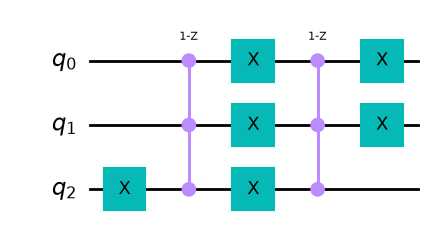

↑ the oracle: for 011 an X on q2 around a controlled Z, for 100 X gates on q0 and q1 around a second one — each block puts a −1 on one marked state


In [4]:
marked_states = ["011", "100"]                           # two of the 2^3 = 8 basis states are "solutions"

oracle = grover_oracle(marked_states)
display(draw(oracle)); print("↑ the oracle: for 011 an X on q2 around a controlled Z, for 100 X gates on q0 and q1 around a second one — each block puts a −1 on one marked state")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `marked_states = ["011", "100"]` | $M = 2$ marked states out of $N = 8$; as bitstrings `q2 q1 q0` |
| the two blocks | `011` has a 0 on q2 → one X on q2; `100` has 0s on q1 and q0 → X on both; the controlled Z between them is drawn as dots joined on three wires (Z is symmetric) |
| `display(draw(oracle))` | the tutorial used `style="iqp"`; all course drawings use the `clifford` style of `draw()` |

</details>


### grover_operator

The built-in Qiskit `grover_operator` function takes an oracle circuit and returns a circuit that is composed of the oracle circuit itself and a circuit that amplifies the states marked by the oracle.  Here, we `decompose` the circuit to see the gates within the operator:


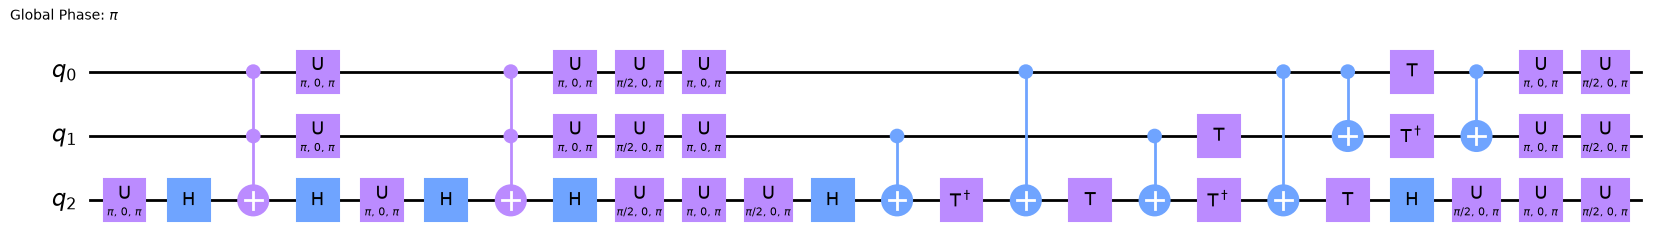

↑ one Grover iteration, decomposed one level: the oracle, then H–X–(multi-controlled Z)–X–H = the diffuser; {'u': 20, 'h': 6, 'cx': 6, 't': 4, 'tdg': 3, 'ccx': 2}


In [5]:
grover_op = grover_operator(oracle)                      # oracle followed by the diffusion operator (reflection about the uniform state)
display(draw(grover_op.decompose())); print(f"↑ one Grover iteration, decomposed one level: the oracle, then H–X–(multi-controlled Z)–X–H = the diffuser; {dict(grover_op.decompose().count_ops())}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `grover_operator(oracle)` | returns a `QuantumCircuit` $Q = D\,O$: the oracle $O$ then the diffuser $D = 2\|s⟩⟨s\| − I$ around the uniform superposition $\|s⟩$ |
| `.decompose()` | expands the composite gates one level, so the diffuser's H, X and multi-controlled gates become visible |
| `count_ops()` | a dict {gate name: number of occurrences} of the decomposed circuit |

</details>


Repeated applications of this `grover_op` circuit amplify the marked states, making them the most probable bit-strings in the output distribution from the circuit.  There is an optimal number of such applications that is determined by the ratio of marked states to total number of possible computational states:


In [6]:
optimal_num_iterations = math.floor(
    math.pi / (4 * math.asin(math.sqrt(len(marked_states) / 2**grover_op.num_qubits)))   # floor(π / 4θ), sin θ = √(M/N)
)
theta = math.asin(math.sqrt(len(marked_states) / 2**grover_op.num_qubits))   # added: the angle θ, for the box below
print(f"θ = {theta:.4f} rad = π/{math.pi / theta:.1f},  π/(4θ) = {math.pi / (4 * theta):.2f},  optimal_num_iterations = {optimal_num_iterations}")
print(f"P(success) after {optimal_num_iterations} iteration(s) = sin²((2k+1)θ) = {math.sin((2 * optimal_num_iterations + 1) * theta) ** 2:.4f}")


θ = 0.5236 rad = π/6.0,  π/(4θ) = 1.50,  optimal_num_iterations = 1
P(success) after 1 iteration(s) = sin²((2k+1)θ) = 1.0000


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `math.asin(math.sqrt(M / N))` | the angle θ between the uniform superposition and the 'unmarked' subspace: $\sin θ = \sqrt{M/N}$ |
| `math.floor(math.pi / (4 * θ))` | the tutorial's iteration count: the rotation by 2θ per iteration should bring the angle $(2k+1)θ$ close to π/2 |
| `2**grover_op.num_qubits` | N = 8 basis states for 3 qubits (`**` = power) |
| added `print`s | the original cell printed nothing; the numbers are checked in the box below |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The optimal number of iterations.** Split the uniform superposition into its marked and unmarked parts,
$$|s\rangle = \sin\theta\,|w\rangle + \cos\theta\,|w^\perp\rangle,\qquad \sin\theta=\sqrt{M/N},$$
where $|w\rangle$ is the normalised sum of the $M$ marked states out of $N=2^n$. The oracle reflects about $|w^\perp\rangle$ and the diffuser about $|s\rangle$: together they rotate the state by $2\theta$ towards $|w\rangle$. After $k$ iterations
$$P_{\rm success}(k)=\sin^2\big((2k+1)\theta\big),$$
which is largest when $(2k+1)\theta\approx\pi/2$, i.e. $k\approx \frac{\pi}{4\theta}-\frac12$; the tutorial takes $k=\lfloor \pi/(4\theta)\rfloor$.

Here $M=2$, $N=8$: $\sin\theta=\sqrt{2/8}=\tfrac12$, so $\theta=\pi/6\approx0.5236$; $\ \pi/(4\theta)=6/4=1.5$; $\ k=\lfloor1.5\rfloor=1$, and
$$P_{\rm success}(1)=\sin^2\!\big(3\cdot\tfrac{\pi}{6}\big)=\sin^2\tfrac{\pi}{2}=1 .$$
One iteration lands *exactly* on the marked subspace: an ideal run gives only `011` and `100`, about half of the shots each (a noisy backend spreads part of the probability over the six other states). The cell prints θ = π/6.0, π/(4θ) = 1.50, `optimal_num_iterations = 1` and P(success) = 1.0000. (For large $N$ and one marked state, $\theta\approx1/\sqrt N$ and $k\approx\frac{\pi}{4}\sqrt N$: the quadratic speed-up.)

</details>


### Full Grover circuit

A complete Grover experiment starts with a Hadamard gate on each qubit; creating an even superposition of all computational basis states, followed the Grover operator (`grover_op`) repeated the optimal number of times.  Here we make use of the `QuantumCircuit.power(INT)` method to repeatedly apply the Grover operator.


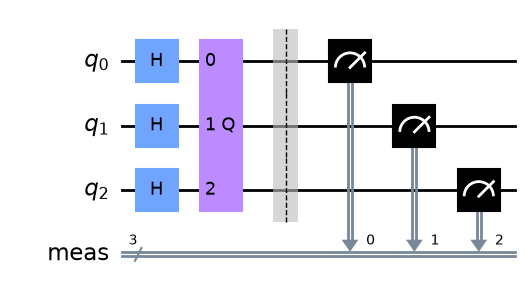

↑ the full search: H on the 3 qubits, the Grover operator Q^1 as one box, then measure_all into the register 'meas'


In [7]:
qc = QuantumCircuit(grover_op.num_qubits)
# Create even superposition of all basis states
qc.h(range(grover_op.num_qubits))
# Apply Grover operator the optimal number of times
qc.compose(grover_op.power(optimal_num_iterations), inplace=True)   # power(k) = the circuit repeated k times
# Measure all qubits
qc.measure_all()                                         # adds a barrier and a new classical register named 'meas'
display(draw(qc)); print(f"↑ the full search: H on the 3 qubits, the Grover operator Q^{optimal_num_iterations} as one box, then measure_all into the register 'meas'")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qc.h(range(n))` | the uniform superposition $\|s⟩$: every one of the 8 states with amplitude $1/\sqrt8$ |
| `grover_op.power(k)` | $Q^k$ as a single block; with k = 1 it is one oracle + one diffuser |
| `qc.measure_all()` | measures every qubit into a register called `meas` — the name used later as `result[0].data.meas` |

</details>


## Step 2. Optimize problem for quantum execution


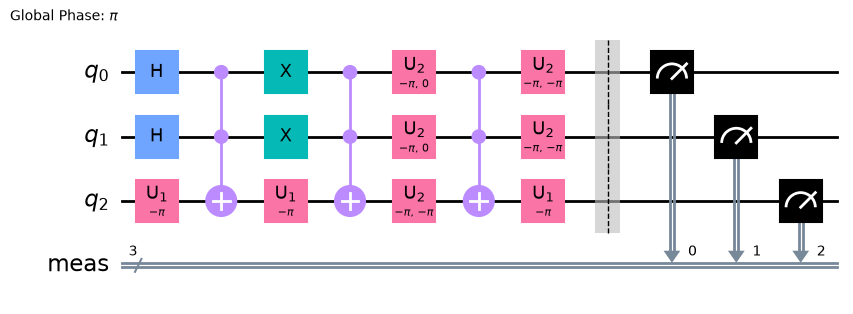

↑ the circuit as aer_simulator will run it: {'u2': 5, 'u1': 3, 'ccx': 3, 'measure': 3, 'h': 2, 'x': 2, 'barrier': 1}, depth 8


In [8]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler: circuit -> the backend's native gates and qubits

target = backend.target                                  # the backend's Target: native gates, qubits, connectivity, error rates
pm = generate_preset_pass_manager(target=target, optimization_level=3)   # optimisation level 3 = most aggressive

circuit_isa = pm.run(qc)                                 # ISA circuit = written in the backend's instruction set
display(draw(circuit_isa, idle_wires=False)); print(f"↑ the circuit as {backend.name} will run it: {dict(circuit_isa.count_ops())}, depth {circuit_isa.depth()}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `backend.target` | everything the transpiler needs to know about the backend: on an IBM device the native gates (`ecr`/`cz`, `sx`, `rz`, `x`) and couplers; on Aer almost any gate |
| `generate_preset_pass_manager(target=..., optimization_level=3)` | a ready-made transpiler: layout, routing, translation, optimisation |
| `idle_wires=False` | hides the unused qubits of a 100+-qubit device |
| `count_ops()`, `depth()` | what actually runs; on the Aer fallback the multi-controlled gates are only decomposed into standard ones |

</details>


## Step 3. Execute using Qiskit Primitives

Amplitude amplification is a sampling problem that is suitable for execution with the [`Sampler`](https://docs.quantum-computing.ibm.com/api/qiskit-ibm-runtime/qiskit_ibm_runtime.SamplerV2) runtime primitive.

Note that the `run()` method of [Qiskit Runtime `SamplerV2`](https://docs.quantum.ibm.com/api/qiskit-ibm-runtime/qiskit_ibm_runtime.SamplerV2)  takes an iterable of `primitive unified blocs (PUBs)`. For sampler, each PUB is an iterable in the format `(circuit, parameter_values)`. However, at a minimum, it takes a list of quantum circuit(s).


In [9]:
# To run on local simulator:
#   1. Use the StatevectorSampler from qiskit.primitives instead   (here: Sampler(mode=AerSimulator()) when there is no account)
sampler = Sampler(mode=backend)                          # Runtime SamplerV2: a device, or local testing mode on the AerSimulator
sampler.options.default_shots = 10_000                   # 10_000 = 10000 (underscores are digit separators)
result = sampler.run([circuit_isa]).result()             # a list of PUBs (here one circuit); .result() waits for the job
dist = result[0].data.meas.get_counts()                  # 'meas' = the register created by measure_all()

def run_circuit(circuit, shots=10_000):
    """Transpile + ideal Aer run + counts in one call (used by the In-depth analysis; always local)."""
    sim = AerSimulator()
    return sim.run(generate_preset_pass_manager(optimization_level=1, backend=sim).run(circuit), shots=shots).result().get_counts()


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `Sampler(mode=backend)` | with an account `backend` is an IBM device and this is a hardware job; offline it is the `AerSimulator` and Qiskit Runtime switches to *local testing mode* — same code, local execution |
| `sampler.options.default_shots` | the number of repetitions for every PUB that does not set its own |
| `result[0].data.meas.get_counts()` | PUB 0, classical register `meas`, as a dict {bitstring: count} |
| `run_circuit(circuit, shots)` | transpile + ideal run + counts, for the In-depth analysis (the IQM edition defines it on `TARGET`); the tutorial comment's 'SatetvectorSampler' typo is fixed |

</details>


## Step 4. Post-process, return result in classical format


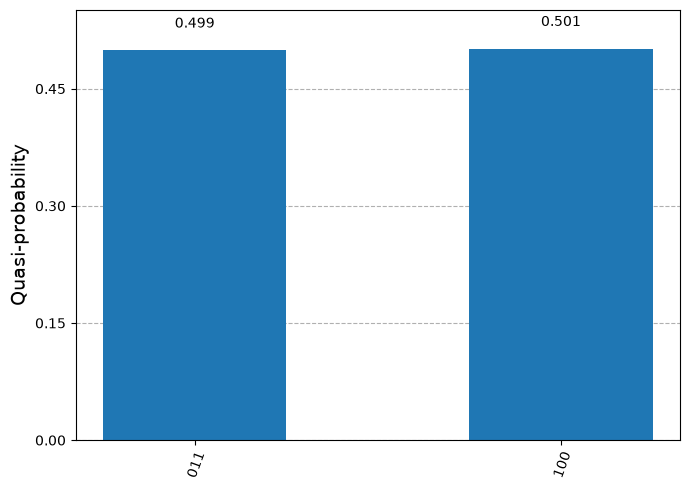

↑ the measured distribution: ideally only the marked states 011 and 100, about ½ each — any other bar is noise
P(marked) = 1.0000   (ideal: sin²(3θ) = 1)


In [10]:
display(plot_distribution(dist)); print("↑ the measured distribution: ideally only the marked states 011 and 100, about ½ each — any other bar is noise")
p_marked = sum(dist.get(s, 0) for s in marked_states) / sum(dist.values())   # dict.get(key, 0): 0 if the key is missing
print(f"P(marked) = {p_marked:.4f}   (ideal: sin²(3θ) = 1)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plot_distribution(dist)` | the bars are counts / shots; the ideal answer is 0.5 on `011` and 0.5 on `100` |
| `sum(dist.get(s, 0) for s in marked_states)` | a generator expression: shots on the marked states; `.get(s, 0)` avoids a `KeyError` when a state never appeared |
| `P(marked)` | 1 on the ideal simulator (box above); on hardware or a noisy model the rest leaks onto the six unmarked states |

</details>


In [11]:
import qiskit_ibm_runtime

qiskit_ibm_runtime.version.get_version_info()            # the installed qiskit-ibm-runtime version


'0.45.1'

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `get_version_info()` | the version string; the tutorial requires qiskit-ibm-runtime 0.22 or later |
| why print it | tutorials depend on fast-moving APIs: the versions tell a reader what the outputs were produced with |

</details>


In [12]:
import qiskit

qiskit.version.get_version_info()                        # the installed Qiskit version (grover_operator needs ≥ 1.3)


'2.1.2'

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qiskit.version.get_version_info()` | the Qiskit version these outputs were produced with |
| Qiskit 2.x | `grover_operator` and `MCMTGate` replace the deprecated `GroverOperator` and `MCMT` of the original tutorial |

</details>


## 🔬 In-depth analysis

1. **Success probability versus iterations.** For the two marked states of this notebook build the search circuit
   with $k = 0,1,\dots,5$ Grover iterations and compute $P(\text{marked})$ from the exact `Statevector`. Compare with
   $\sin^2((2k+1)\theta)$ of the box: the probability *oscillates*, so more iterations are not better.
2. **One marked state out of 16.** With 4 qubits and `marked = ["1011"]`, compute the tutorial's optimal $k$ and the
   predicted $P_{\rm success}$, then run the circuit with `run_circuit(circuit, shots=4000)` and measure it.
3. **When Grover does nothing.** Mark half of the space, `["000", "011", "101", "110"]` ($M/N = 1/2$): what are
   $\theta$, the tutorial's $k$ and $P_{\rm success}(k)$? Check with the state vector and explain.

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [13]:
# 🔬 In-depth analysis — your code here



In [14]:
# Reference solution
from qiskit.quantum_info import Statevector              # exact state vector (no sampling, no noise)

def grover_circuit(marked, k, measure=True):
    """H on every qubit + k Grover iterations for the given marked bit-strings."""
    op = grover_operator(grover_oracle(marked))
    c = QuantumCircuit(op.num_qubits)
    c.h(range(op.num_qubits))
    c.compose(op.power(k), inplace=True)                 # power(0) = empty circuit
    if measure:
        c.measure_all()
    return c

def p_exact(marked, k):
    probs = Statevector(grover_circuit(marked, k, measure=False)).probabilities_dict()   # {bitstring: probability}
    return sum(probs.get(s, 0) for s in marked)

def k_opt(M, N):
    th = math.asin(math.sqrt(M / N))
    return th, math.floor(math.pi / (4 * th) + 1e-9)    # + 1e-9: guard against rounding, e.g. π/(4·π/4) = 0.9999999999999999

# (1) oscillation of P(marked) with the number of iterations
th, _ = k_opt(len(marked_states), 8)
print("(1) k, P(marked) from the state vector, sin²((2k+1)θ):")
for k in range(6):
    print(f"    k = {k}: {p_exact(marked_states, k):.4f}   formula {math.sin((2 * k + 1) * th) ** 2:.4f}")

# (2) one marked state out of 16
marked16 = ["1011"]
th16, k16 = k_opt(1, 16)
counts16 = run_circuit(grover_circuit(marked16, k16), shots=4000)
print(f"(2) N = 16, M = 1: θ = {th16:.4f}, k = floor(π/4θ) = floor({math.pi / (4 * th16):.3f}) = {k16}, "
      f"predicted P = sin²({2 * k16 + 1}θ) = {math.sin((2 * k16 + 1) * th16) ** 2:.4f}, "
      f"state vector {p_exact(marked16, k16):.4f}, measured {counts16.get('1011', 0) / 4000:.4f}")

# (3) half of the space marked
half = ["000", "011", "101", "110"]
th_h, k_h = k_opt(len(half), 8)
print(f"(3) M/N = 1/2: θ = {th_h:.4f} = π/{math.pi / th_h:.0f}, k = {k_h}, "
      f"P(k=0) = {p_exact(half, 0):.4f}, P(k={k_h}) = {p_exact(half, k_h):.4f} (formula {math.sin(3 * th_h) ** 2:.4f})")


(1) k, P(marked) from the state vector, sin²((2k+1)θ):
    k = 0: 0.2500   formula 0.2500
    k = 1: 1.0000   formula 1.0000
    k = 2: 0.2500   formula 0.2500
    k = 3: 0.2500   formula 0.2500
    k = 4: 1.0000   formula 1.0000
    k = 5: 0.2500   formula 0.2500


(2) N = 16, M = 1: θ = 0.2527, k = floor(π/4θ) = floor(3.108) = 3, predicted P = sin²(7θ) = 0.9613, state vector 0.9613, measured 0.9577
(3) M/N = 1/2: θ = 0.7854 = π/4, k = 1, P(k=0) = 0.5000, P(k=1) = 0.5000 (formula 0.5000)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `grover_circuit(marked, k)` | the circuit of this notebook as a function of the marked states and of the number of iterations |
| `Statevector(...).probabilities_dict()` | exact probabilities keyed by bitstrings in the same `q_{n−1}…q_0` order as the counts |
| (1) 0.25, 1, 0.25, 0.25, 1, 0.25 | $\sin^2((2k+1)\pi/6)$: the state rotates *past* the marked subspace and comes back — overshooting is as bad as stopping early |
| (2) k = 3, P ≈ 0.96 | θ = arcsin(1/4); `run_circuit` samples it: ideal Aer in the IBM edition, `TARGET` in the IQM edition — about 0.96 on the ideal simulator, but only about 0.1 on the noisy fake_apollo, close to the random-guess 1/16: three iterations of a 4-qubit oracle and diffuser are a few hundred CZs |
| (3) θ = π/4, k = 1 | one iteration rotates by π/2 from angle π/4 to 3π/4: $\sin^2(3π/4) = 1/2$, exactly the probability *without* Grover — with half the space marked, random guessing is already as good |

</details>


## Tutorial Survey

<table style="width: 100%;">
<tbody>
<tr>
<td style="width: 10%;"><img src="https://learning-api.quantum.ibm.com/assets/53171443-b07b-4ae6-a4be-9aec32a854f5" alt="Survey" width="100%" height="100%"></td>
<td style="width: 80%;"><strong><a title="Tutorial Survey" href="https://your.feedback.ibm.com/jfe/form/SV_9oxLZ9HicmqM54a" target="_blank">Tutorial Survey</a></strong><br>Please take one minute to provide feedback on this tutorial. Your insights will help us improve our content offerings and user experience.</td>
</tr>
</tbody>
</table>
